# 07 · Luzern: izbira značilk in primerjava modelov

V tem zvezku sem primerjal napovedovanje prometnega toka za 15 in 30 minut vnaprej ter model izbral po najmanjšem validacijskem MAE.


## 1. Nastavitve

Za ponovljivost sem nastavil seed=42, učenje omejil na 300.000 primerov in podatke razdelil po času.


In [1]:
from pathlib import Path
import os
import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from threadpoolctl import threadpool_limits

SEED = 42
TRAIN_END = pd.Timestamp('2015-09-13')
VAL_END = pd.Timestamp('2015-11-07')
YEAR_END = pd.Timestamp('2016-01-01')
HORIZONS = (15, 30)
TRAIN_SAMPLE_SIZE = 300_000
SVR_SAMPLE_SIZE = 5_000
EVALUATION_SAMPLE_SIZE = 20_000
ORIGIN_STEP_MINUTES = 15
WEATHER_DELAY_HOURS = 2
N_JOBS = 2

required = ['luzern_raw.parquet', 'luzern_weather_2015.csv', 'luzern_calendar_2015.csv']
configured = os.environ.get('TRAFFIC_TWIN_DATA_DIR')
candidates = [Path(configured)] if configured else [Path.cwd(), Path.cwd().parent, Path('/content')]
DATA_DIR = next((p.resolve() for p in candidates if all((p / f).is_file() for f in required)), None)
if DATA_DIR is None:
    raise FileNotFoundError('Set TRAFFIC_TWIN_DATA_DIR to the folder containing the three Luzern files.')
OUTPUT_DIR = DATA_DIR / 'outputs/07_model_comparison'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRAFFIC_PATH = DATA_DIR / required[0]



## 2. Pregled in priprava podatkov

S pandas sem pregledal meritve po detektorjih in iz učnega obdobja izbral detektorje z dovolj zanesljivimi dnevi.


In [2]:
def read_detector(detid):
    # Project columns and filter one detector to keep memory usage bounded.
    raw = pd.read_parquet(TRAFFIC_PATH, engine='pyarrow', dtype_backend='pyarrow',
                          columns=['day', 'interval', 'flow', 'occ', 'error', 'speed'],
                          filters=[('detid', '==', detid)])
    raw['interval'] = raw['interval'].astype('Int64')
    raw['day'] = pd.to_datetime(raw['day'])
    raw['timestamp'] = raw.day + pd.to_timedelta(raw.interval.to_numpy(dtype=float), unit='s')
    return raw

def valid_measurements(raw):
    return (raw.error.isna() & raw.flow.between(0, 99998) & raw.occ.between(0, 1)
            & raw.interval.between(0, 86400) & raw.interval.mod(180).eq(0)).fillna(False)

detector_keys = pd.read_parquet(TRAFFIC_PATH, columns=['detid'], engine='pyarrow',
                                dtype_backend='pyarrow', read_dictionary=['detid'])
all_detector_ids = sorted(detector_keys.detid.dropna().unique().tolist())
del detector_keys
quality_totals = {'rows': 0, 'detectors': len(all_detector_ids), 'first_day': None,
                  'last_day': None, 'flagged': 0, 'available_speed': 0,
                  'boundary_rows': 0, 'invalid_values': 0}
selection = []
for detid in all_detector_ids:
    raw = read_detector(detid)
    quality_totals['rows'] += len(raw)
    first, last = raw.day.min(), raw.day.max()
    quality_totals['first_day'] = first if quality_totals['first_day'] is None else min(first, quality_totals['first_day'])
    quality_totals['last_day'] = last if quality_totals['last_day'] is None else max(last, quality_totals['last_day'])
    quality_totals['flagged'] += int(raw.error.notna().sum())
    quality_totals['available_speed'] += int(raw.speed.notna().sum())
    quality_totals['boundary_rows'] += int(raw.interval.eq(86400).sum())
    invalid = raw.flow.eq(99999) | raw.flow.lt(0) | ~raw.occ.between(0, 1)
    quality_totals['invalid_values'] += int(invalid.fillna(False).sum())
    # Keep reporting day and reconstructed timestamp inside the training period.
    mask = valid_measurements(raw) & raw.day.lt(TRAIN_END) & raw.timestamp.lt(TRAIN_END)
    daily = raw.loc[mask].groupby('day').interval.nunique()
    reliable_days = int(daily.ge(400).sum())
    if reliable_days >= 175:
        selection.append({'detid': detid, 'reliable_days': reliable_days,
                          'valid_observations': int(daily.sum())})
quality = pd.DataFrame([quality_totals])
detector_quality = pd.DataFrame(selection).sort_values('detid').reset_index(drop=True)
assert not detector_quality.empty, 'No eligible detectors: inspect input data.'
detector_ids = detector_quality.detid.tolist()
detector_mapping = {detid: i for i, detid in enumerate(detector_ids)}
assert len(detector_ids) < 255
del raw
display(quality)
print('Selected using training data only:', len(detector_ids))
display(detector_quality.head())


,rows,detectors,first_day,last_day,flagged,available_speed,boundary_rows,invalid_values
0,26878297,158,2015-01-01,2015-12-31,9065941,0,56026,124499


Selected using training data only: 79


,detid,reliable_days,valid_observations
0,ig11FD100_D3,193,98372
1,ig11FD100_D31,250,109883
2,ig11FD100_D32,187,102223
3,ig11FD100_D33,250,113415
4,ig11FD100_D34,250,113509


## 3. Izbira značilk

Vključil sem trenutni in pretekli promet, koledar ter vremenske podatke z dvournim zamikom.


In [3]:
weather_cols = ['temperature_2m_c', 'precipitation_mm', 'relative_humidity_2m_pct', 'wind_speed_10m_kmh']
weather = pd.read_csv(DATA_DIR / required[1], parse_dates=['time_local'])
calendar = pd.read_csv(DATA_DIR / required[2], parse_dates=['date'])
assert not weather.time_local.duplicated().any(), 'Ambiguous weather hours; resolve DST duplicates first.'
assert not calendar.date.duplicated().any()
assert weather[weather_cols].notna().all().all()
assert calendar[['is_weekend', 'is_holiday', 'is_workday']].isin([0, 1]).all().all()
weather = weather.set_index('time_local').sort_index()
calendar = calendar.set_index('date').sort_index()
timeline = pd.date_range('2015-01-01', YEAR_END, freq='3min', inclusive='left')

def split_at(timestamps):
    return np.select([timestamps < TRAIN_END, timestamps < VAL_END], ['train', 'validation'], default='test')

parts, audit_rows, history_parts = [], [], []
for detid in detector_ids:
    # Conflicting valid duplicates are masked, rather than choosing an arbitrary value.
    source = read_detector(detid)
    source = source.loc[valid_measurements(source)]
    raw = source.groupby('timestamp', sort=True).agg(
        flow=('flow', 'min'), occ=('occ', 'min'), source_rows=('flow', 'size'),
        flow_unique=('flow', 'nunique'), occ_unique=('occ', 'nunique'))
    conflict = raw.flow_unique.ne(1) | raw.occ_unique.ne(1)
    raw.loc[conflict, ['flow', 'occ']] = np.nan
    del source
    s = raw[['flow', 'occ']].reindex(timeline).astype('float32')
    assert s.index.to_series().diff().dropna().eq(pd.Timedelta(minutes=3)).all()
    audit_rows.append({'detid': detid, 'grid_slots': len(s), 'valid_slots': int(s.flow.notna().sum()),
                       'duplicate_excess': int((raw.source_rows - 1).sum()),
                       'conflicting_timestamps': int(raw.flow.isna().sum())})
    # Learn a historical baseline from all valid TRAIN measurements, not future targets.
    hist = s.loc[s.index < TRAIN_END, ['flow']].dropna().copy()
    hist['weekday'], hist['hour'] = hist.index.day_of_week, hist.index.hour
    hist = hist.groupby(['weekday', 'hour']).flow.agg(['mean', 'count']).reset_index()
    hist['detid'] = detid
    history_parts.append(hist)

    f = s.copy()
    for lag in [1, 5, 10, 20, 480, 3360]:
        f[f'flow_lag_{lag}'] = s.flow.shift(lag)
    for lag in [1, 5, 10]:
        f[f'occ_lag_{lag}'] = s.occ.shift(lag)
    for window in [5, 10, 20]:
        roll = s.flow.rolling(window, min_periods=window)
        f[f'flow_mean_{window}'] = roll.mean()
        f[f'flow_std_{window}'] = roll.std()
    f['occ_mean_5'] = s.occ.rolling(5, min_periods=5).mean()
    f['flow_change_5'] = s.flow - s.flow.shift(5)
    for horizon in HORIZONS:
        f[f'target_{horizon}m'] = s.flow.shift(-horizon // 3)

    # Require uninterrupted valid recent hour, current reading, seasonal lags and both targets.
    eligible = s.flow.rolling(21, min_periods=21).count().eq(21)
    eligible &= f.notna().all(axis=1)
    eligible &= (f.index.minute % ORIGIN_STEP_MINUTES == 0)
    f = f.loc[eligible].copy()
    f['timestamp'] = f.index
    f['split'] = split_at(f.index)
    # Purge boundary rows for BOTH horizons: no training/validation label crosses a split.
    future = f.index + pd.Timedelta(minutes=max(HORIZONS))
    f = f.loc[(f['split'].to_numpy() == split_at(future)) & (future < YEAR_END)].copy()
    f['detid'], f['detector_code'] = detid, detector_mapping[detid]
    # Separate count targets: sum the next 5/10 readings on the full 3-minute grid.
    # Append AFTER point-forecast eligibility so the existing comparison stays identical.
    for horizon in HORIZONS:
        steps = horizon // 3
        future_sum = s.flow.rolling(steps, min_periods=steps).sum().shift(-steps)
        f[f'count_target_{horizon}m'] = future_sum.reindex(f.index) / 20
    weather_time = f.index.floor('h') - pd.Timedelta(hours=WEATHER_DELAY_HOURS)
    w = weather.reindex(weather_time)[weather_cols]
    assert (weather_time + pd.Timedelta(hours=WEATHER_DELAY_HOURS) <= f.index).all()
    assert w.notna().all().all(), 'Missing delayed weather: inspect source hours.'
    for col in weather_cols:
        f[col] = w[col].to_numpy(dtype='float32')
    parts.append(f.reset_index(drop=True))
    if len(parts) % 20 == 0:
        print(f'Prepared {len(parts)}/{len(detector_ids)} detectors', flush=True)

data = pd.concat(parts, ignore_index=True)
history = pd.concat(history_parts, ignore_index=True)
audit = pd.DataFrame(audit_rows)
del parts, history_parts, raw, s, f
gc.collect()
assert not data.duplicated(['detid', 'timestamp']).any()
assert set(data.split) == {'train', 'validation', 'test'}
numeric = data.select_dtypes(include='number').columns
data[numeric] = data[numeric].astype('float32')
display(data.groupby('split', sort=False).agg(samples=('detid', 'size'), detectors=('detid', 'nunique'),
    first_origin=('timestamp', 'min'), last_origin=('timestamp', 'max')))
display(audit.sum(numeric_only=True).to_frame('total'))
print('No interpolation or zero filling. Results apply to complete-history cases only.')


Prepared 20/79 detectors


Prepared 40/79 detectors


Prepared 60/79 detectors


,samples,detectors,first_origin,last_origin
split,,,,
train,1048957,79,2015-01-08 06:15:00,2015-09-12 23:15:00
validation,230199,79,2015-09-13 00:00:00,2015-11-06 23:15:00
test,238927,79,2015-11-07 00:00:00,2015-12-31 23:15:00


,total
grid_slots,13840800
valid_slots,12109240
duplicate_excess,0
conflicting_timestamps,0


No interpolation or zero filling. Results apply to complete-history cases only.


## 4. Primerjava modelov

Za preverjanje nelinearnih vzorcev sem primerjal RandomForestRegressor, Support Vector Regression z jedrom RBF in XGBRegressor ter jih ocenil ob dosedanjih modelih.


SVR z jedrom RBF sem zaradi [računske zahtevnosti](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html) učil na 5.000 primerih, druge modele pa na do 300.000, zato primerjava vključuje tudi različne učne obsege.


Vse modele sem primerjal na istih 20.000 validacijskih in 20.000 testnih primerih za posamezni cilj, nato pa izbrani model preveril še na celotnem testnem naboru.


In [4]:
traffic_features = ['detector_code', 'flow', 'occ'] + [
    c for c in data.columns if c.startswith(('flow_lag_', 'occ_lag_', 'flow_mean_', 'flow_std_'))
] + ['occ_mean_5', 'flow_change_5']
calendar_features = ['hour_sin', 'hour_cos', 'weekday_sin', 'weekday_cos', 'month',
                     'is_weekend', 'is_holiday', 'is_workday']
feature_sets = {
    'traffic': traffic_features,
    'calendar': traffic_features + calendar_features,
    'weather': traffic_features + calendar_features + weather_cols,
}

def horizon_frame(horizon):
    frame = data.copy()
    target_time = frame.timestamp + pd.Timedelta(minutes=horizon)
    fractional_hour = target_time.dt.hour + target_time.dt.minute / 60
    frame['hour_sin'] = np.sin(2 * np.pi * fractional_hour / 24)
    frame['hour_cos'] = np.cos(2 * np.pi * fractional_hour / 24)
    frame['weekday_sin'] = np.sin(2 * np.pi * target_time.dt.day_of_week / 7)
    frame['weekday_cos'] = np.cos(2 * np.pi * target_time.dt.day_of_week / 7)
    frame['month'] = target_time.dt.month
    known_calendar = calendar.reindex(pd.DatetimeIndex(target_time.dt.normalize()))
    for col in ['is_weekend', 'is_holiday', 'is_workday']:
        frame[col] = known_calendar[col].to_numpy()
    assert frame[feature_sets['weather']].notna().all().all()
    key = pd.MultiIndex.from_arrays([frame.detid, target_time.dt.day_of_week, target_time.dt.hour],
                                    names=['detid', 'weekday', 'hour'])
    profile = history.set_index(['detid', 'weekday', 'hour'])['mean']
    frame['historical_prediction'] = profile.reindex(key).to_numpy()
    # Fallback for an unseen training calendar cell: weighted TRAIN detector mean.
    weighted = history.assign(total=history['mean'] * history['count']).groupby('detid')[['total', 'count']].sum()
    fallback = frame.detid.map(weighted.total / weighted['count'])
    frame['historical_prediction'] = frame.historical_prediction.fillna(fallback)
    assert frame.historical_prediction.notna().all()
    return frame

def make_estimator(kind, features):
    numeric = [f for f in features if f != 'detector_code']
    if kind in ['ridge', 'rf', 'svr', 'xgb']:
        inputs = ColumnTransformer([
            ('id', OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float32), ['detector_code']),
            ('numeric', StandardScaler() if kind in ['ridge', 'svr'] else 'passthrough', numeric),
        ])
        if kind == 'ridge':
            return make_pipeline(inputs, Ridge(alpha=10))
        if kind == 'rf':
            return make_pipeline(inputs, RandomForestRegressor(
                n_estimators=40, max_depth=16, min_samples_leaf=10, max_features=0.8,
                max_samples=0.33, n_jobs=N_JOBS, random_state=SEED))
        if kind == 'svr':
            return TransformedTargetRegressor(
                regressor=make_pipeline(inputs, SVR(kernel='rbf', C=10, epsilon=0.1, cache_size=512)),
                transformer=StandardScaler())
        return make_pipeline(inputs, XGBRegressor(
            n_estimators=400, max_depth=6, learning_rate=0.05, min_child_weight=20,
            subsample=0.8, colsample_bytree=0.8, objective='reg:absoluteerror',
            tree_method='hist', n_jobs=N_JOBS, random_state=SEED))
    return HistGradientBoostingRegressor(
        max_iter=150, learning_rate=0.08, max_leaf_nodes=31, min_samples_leaf=40,
        l2_regularization=1.0, categorical_features=['detector_code'],
        early_stopping=False, random_state=SEED)

def evaluation_sample(frame):
    return frame.sample(n=min(EVALUATION_SAMPLE_SIZE, len(frame)), random_state=SEED).sort_index()

def model_training_rows(train, kind):
    # A true RBF SVR is computationally expensive; disclose its smaller training budget.
    return train.sample(n=min(SVR_SAMPLE_SIZE, len(train)), random_state=SEED) if kind == 'svr' else train

specs = {
    'Ridge + calendar': ('calendar', 'ridge'),
    'HistGradientBoostingRegressor (promet)': ('traffic', 'hgb'),
    'HistGradientBoostingRegressor (+koledar)': ('calendar', 'hgb'),
    'HistGradientBoostingRegressor (+koledar+vreme)': ('weather', 'hgb'),
    'RandomForestRegressor': ('weather', 'rf'),
    'Support Vector Regression (RBF)': ('weather', 'svr'),
    'XGBoost (XGBRegressor)': ('weather', 'xgb'),
}

def score(y, pred, model, horizon, split, fit_seconds=0):
    pred = np.maximum(np.asarray(pred), 0)  # Same physical non-negativity rule for every model.
    assert len(y) == len(pred) and np.isfinite(pred).all()
    mae = mean_absolute_error(y, pred)
    return {'model': model, 'horizon_min': horizon, 'split': split,
            'MAE': mae, 'RMSE': float(np.sqrt(mean_squared_error(y, pred))),
            'MAE_vehicles_per_3min_lane': mae / 20, 'samples': len(y),
            'fit_seconds': fit_seconds}




In [5]:
validation_rows, fitted, winners = [], {}, {}
train_indices = (data.loc[data.split.eq('train')]
                 .sample(n=min(TRAIN_SAMPLE_SIZE, int(data.split.eq('train').sum())), random_state=SEED).index)
assert data.loc[train_indices, 'split'].eq('train').all()
assert data.loc[train_indices].detid.nunique() == len(detector_ids)

for horizon in HORIZONS:
    frame = horizon_frame(horizon)
    train = frame.loc[train_indices]
    val = evaluation_sample(frame.loc[frame.split.eq('validation')])
    y = val[f'target_{horizon}m']
    fitted[horizon] = {}
    for name, column in [('Persistence', 'flow'), ('Historical average', 'historical_prediction')]:
        validation_rows.append(score(y, val[column], name, horizon, 'validation'))
    for name, (group, kind) in specs.items():
        features = feature_sets[group]
        model = make_estimator(kind, features)
        start = time.perf_counter()
        with threadpool_limits(limits=N_JOBS):
            training = model_training_rows(train, kind)
            model.fit(training[features], training[f'target_{horizon}m'])
            pred = model.predict(val[features])
        seconds = time.perf_counter() - start
        fitted[horizon][name] = model
        row = score(y, pred, name, horizon, 'validation', seconds)
        row['training_samples'] = len(training)
        validation_rows.append(row)
        print(f'{horizon}m | {name}: MAE={validation_rows[-1]["MAE"]:.3f} ({seconds:.1f}s)', flush=True)
    ranked = pd.DataFrame(validation_rows).query('horizon_min == @horizon').sort_values(['MAE', 'RMSE', 'model'])
    assert ranked.samples.nunique() == 1
    winners[horizon] = ranked.iloc[0]['model']
    print(f'Izbran model za {horizon} min: {winners[horizon]}', flush=True)
    del frame, train, val, training
    gc.collect()

validation_results = pd.DataFrame(validation_rows).sort_values(['horizon_min', 'MAE', 'RMSE'])
validation_results.to_csv(OUTPUT_DIR / 'validation_metrics.csv', index=False)
display(validation_results[['horizon_min', 'model', 'MAE', 'RMSE', 'samples', 'training_samples']].round(3))


15m | Ridge + calendar: MAE=81.607 (1.9s)


15m | HistGradientBoostingRegressor (promet): MAE=81.439 (9.2s)


15m | HistGradientBoostingRegressor (+koledar): MAE=76.345 (14.3s)


15m | HistGradientBoostingRegressor (+koledar+vreme): MAE=76.291 (14.5s)


15m | RandomForestRegressor: MAE=79.100 (82.7s)


15m | Support Vector Regression (RBF): MAE=95.298 (41.5s)


... (7 outputs left out)

30m | Support Vector Regression (RBF): MAE=101.375 (36.3s)


30m | XGBoost (XGBRegressor): MAE=79.056 (47.8s)


Izbran model za 30 min: HistGradientBoostingRegressor (+koledar+vreme)


,horizon_min,model,MAE,RMSE,samples,training_samples
5,15,HistGradientBoostingRegressor (+koledar+vreme),76.291,97.181,20000,300000.0
4,15,HistGradientBoostingRegressor (+koledar),76.345,97.239,20000,300000.0
8,15,XGBoost (XGBRegressor),77.290,98.716,20000,300000.0
6,15,RandomForestRegressor,79.100,100.918,20000,300000.0
3,15,HistGradientBoostingRegressor (promet),81.439,103.862,20000,300000.0
2,15,Ridge + calendar,81.607,104.322,20000,300000.0
1,15,Historical average,82.936,106.893,20000,NaN
7,15,Support Vector Regression (RBF),95.298,121.105,20000,5000.0
0,15,Persistence,104.217,133.523,20000,NaN
14,30,HistGradientBoostingRegressor (+koledar+vreme),77.532,99.229,20000,300000.0


## 5. Rezultati na validaciji

Na validaciji sem za vsak horizont izbral model z najmanjšim MAE.


,horizon_min,added_features,MAE_before,MAE_after,MAE_reduction,improvement_pct
0,15,Calendar,81.439,76.345,5.094,6.256
1,15,Delayed weather,76.345,76.291,0.054,0.071
2,30,Calendar,86.897,77.552,9.344,10.753
3,30,Delayed weather,77.552,77.532,0.020,0.026


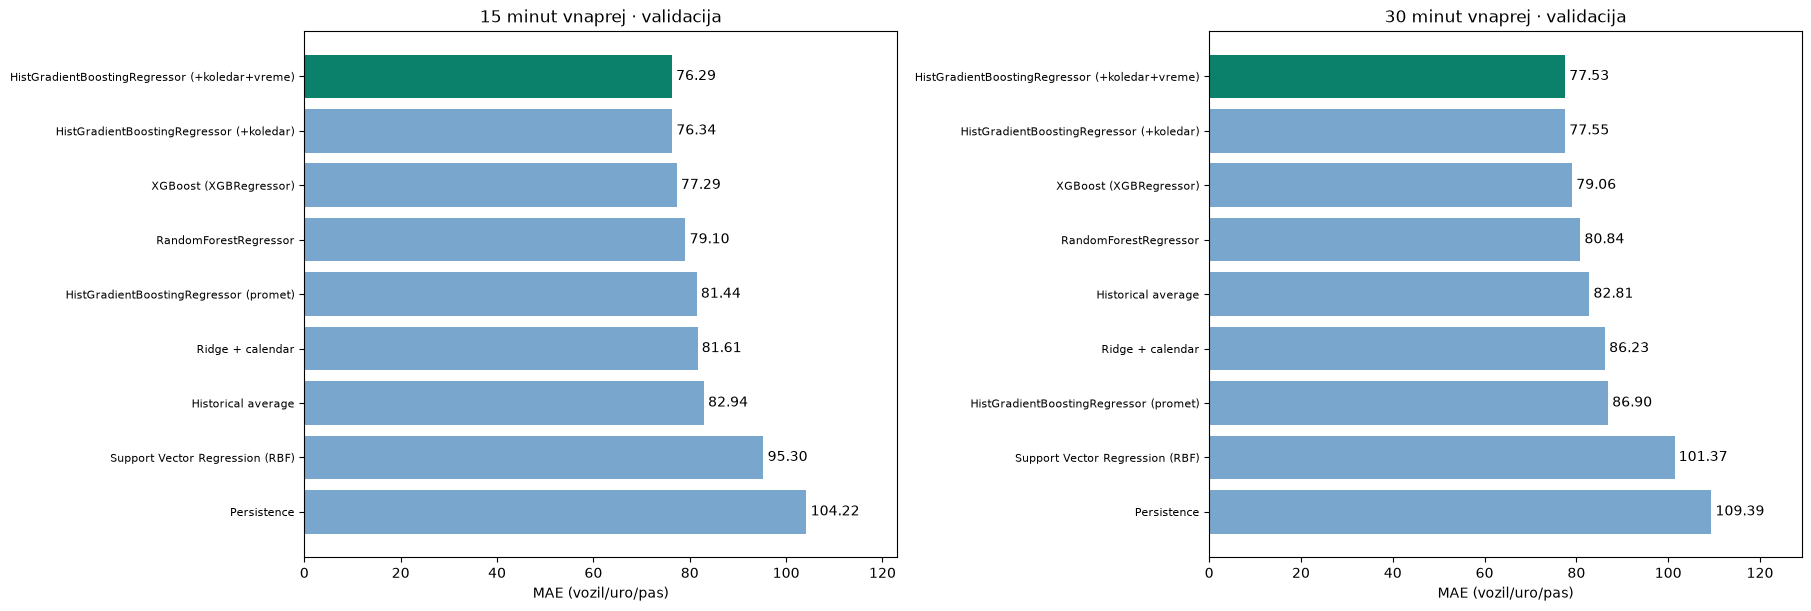

In [6]:
ablation_rows = []
for horizon in HORIZONS:
    v = validation_results.query('horizon_min == @horizon').set_index('model')
    for before, after, addition in [
        ('HistGradientBoostingRegressor (promet)', 'HistGradientBoostingRegressor (+koledar)', 'Calendar'),
        ('HistGradientBoostingRegressor (+koledar)', 'HistGradientBoostingRegressor (+koledar+vreme)', 'Delayed weather'),
    ]:
        reduction = v.loc[before, 'MAE'] - v.loc[after, 'MAE']
        ablation_rows.append({'horizon_min': horizon, 'added_features': addition,
            'MAE_before': v.loc[before, 'MAE'], 'MAE_after': v.loc[after, 'MAE'],
            'MAE_reduction': reduction, 'improvement_pct': 100 * reduction / v.loc[before, 'MAE']})
ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(OUTPUT_DIR / 'feature_ablation.csv', index=False)
display(ablation.round(3))

fig, axes = plt.subplots(1, 2, figsize=(18, 6), layout='constrained')
for ax, horizon in zip(axes, HORIZONS):
    values = validation_results.query('horizon_min == @horizon').sort_values('MAE', ascending=False)
    colors = ['#0b806b' if n == winners[horizon] else '#79a6cc' for n in values.model]
    bars = ax.barh(values.model, values.MAE, color=colors)
    ax.tick_params(axis='y', labelsize=8)
    ax.bar_label(bars, fmt='%.2f', padding=3)
    ax.set(title=f'{horizon} minut vnaprej · validacija', xlabel='MAE (vozil/uro/pas)')
    ax.set_xlim(0, values.MAE.max() * 1.18)
fig.savefig(OUTPUT_DIR / 'validation_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


### 5.1 Koliko sta pomagala koledar in vreme?

Z istim HistGradientBoostingRegressor sem preveril, koliko dodani koledar in vreme zmanjšata validacijski MAE.


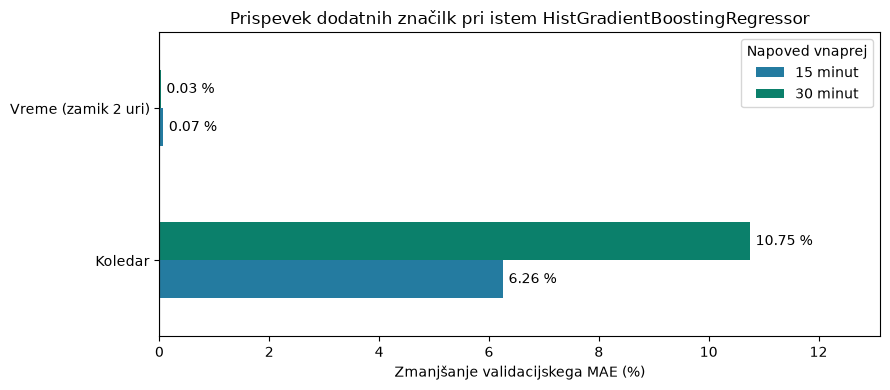

In [7]:
feature_labels = {'Calendar': 'Koledar', 'Delayed weather': 'Vreme (zamik 2 uri)'}
gains = ablation.pivot(index='added_features', columns='horizon_min', values='improvement_pct')
gains = gains.reindex(['Calendar', 'Delayed weather']).rename(index=feature_labels)
gains.columns = [f'{horizon} minut' for horizon in gains.columns]
ax = gains.plot.barh(figsize=(9, 4), color=['#247ba0', '#0b806b'])
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.2f %%', padding=4)
ax.axvline(0, color='#555555', linewidth=0.8)
ax.set(title='Prispevek dodatnih značilk pri istem HistGradientBoostingRegressor',
       xlabel='Zmanjšanje validacijskega MAE (%)', ylabel='')
ax.legend(title='Napoved vnaprej')
ax.margins(x=0.22)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'feature_contribution.png', dpi=150, bbox_inches='tight')
plt.show()


## 6. Preverjanje na testnem obdobju

Izbrana modela sem preveril na testnem obdobju in izbire glede na test nisem spreminjal.


In [8]:
test_rows, forecast_examples, selected_rows = [], [], []
for horizon in HORIZONS:
    frame = horizon_frame(horizon)
    full_test = frame.loc[frame.split.eq('test')]
    test = evaluation_sample(full_test)
    target = f'target_{horizon}m'
    predictions = {'Persistence': test.flow, 'Historical average': test.historical_prediction}
    for name, model in fitted[horizon].items():
        features = feature_sets[specs[name][0]]
        with threadpool_limits(limits=N_JOBS):
            predictions[name] = model.predict(test[features])
    for name, pred in predictions.items():
        row = score(test[target], pred, name, horizon, 'test')
        row['selected_on_validation'] = name == winners[horizon]
        test_rows.append(row)

    # Evaluate the already-selected winner on ALL eligible test cases.
    winner = winners[horizon]
    if winner in specs:
        features = feature_sets[specs[winner][0]]
        with threadpool_limits(limits=N_JOBS):
            full_prediction = np.maximum(fitted[horizon][winner].predict(full_test[features]), 0)
    else:
        full_prediction = full_test['flow' if winner == 'Persistence' else 'historical_prediction'].to_numpy()
    row = score(full_test[target], full_prediction, winner, horizon, 'full_test')
    row['validation_MAE'] = validation_results.loc[
        validation_results.horizon_min.eq(horizon) & validation_results.model.eq(winner), 'MAE'].iloc[0]
    selected_rows.append(row)
    detector_test = full_test.loc[full_test.detid.eq(detector_ids[0])]
    if not detector_test.empty:
        example_day = detector_test.timestamp.min().normalize()
        mask = full_test.detid.eq(detector_ids[0]) & full_test.timestamp.dt.normalize().eq(example_day)
        example = full_test.loc[mask, ['detid', 'timestamp', 'flow', target]].copy()
        example['observed'] = example.pop(target)
        example['predicted'] = full_prediction[mask.to_numpy()]
        example['target_time'] = example.timestamp + pd.Timedelta(minutes=horizon)
        example['horizon_min'] = horizon
        forecast_examples.append(example)
    joblib.dump({'model_name': winner, 'model': fitted[horizon].get(winner),
        'features': feature_sets[specs[winner][0]] if winner in specs else [],
        'detector_mapping': detector_mapping, 'history': history, 'horizon_minutes': horizon,
        'weather_delay_hours': WEATHER_DELAY_HOURS, 'clip_predictions_at_zero': True},
        OUTPUT_DIR / f'best_model_{horizon}m.joblib')
    del frame, full_test, test, predictions
    gc.collect()

test_results = pd.DataFrame(test_rows)
assert test_results.groupby('horizon_min').samples.nunique().eq(1).all()
test_results.to_csv(OUTPUT_DIR / 'test_metrics.csv', index=False)
print('Vsi modeli: isti testni vzorec.')
display(test_results[['horizon_min', 'model', 'MAE', 'RMSE', 'samples', 'selected_on_validation']].round(3))
selected = pd.DataFrame(selected_rows)
selected.to_csv(OUTPUT_DIR / 'selected_models.csv', index=False)
print('Izbrana modela: celoten testni nabor.')
display(selected[['horizon_min', 'model', 'MAE', 'RMSE', 'samples', 'validation_MAE']].round(3))


Vsi modeli: isti testni vzorec.


,horizon_min,model,MAE,RMSE,samples,selected_on_validation
0,15,Persistence,103.004,131.793,20000,False
1,15,Historical average,88.214,114.417,20000,False
2,15,Ridge + calendar,81.179,103.926,20000,False
3,15,HistGradientBoostingRegressor (promet),81.341,103.926,20000,False
4,15,HistGradientBoostingRegressor (+koledar),76.781,98.123,20000,False
5,15,HistGradientBoostingRegressor (+koledar+vreme),76.684,98.033,20000,True
6,15,RandomForestRegressor,79.394,101.471,20000,False
7,15,Support Vector Regression (RBF),102.173,130.031,20000,False
8,15,XGBoost (XGBRegressor),77.583,99.233,20000,False
9,30,Persistence,107.671,138.751,20000,False


Izbrana modela: celoten testni nabor.


,horizon_min,model,MAE,RMSE,samples,validation_MAE
0,15,HistGradientBoostingRegressor (+koledar+vreme),76.254,97.338,238927,76.291
1,30,HistGradientBoostingRegressor (+koledar+vreme),77.541,99.175,238927,77.532


### 6.1 Kako se napoved ujema z meritvami?

Na prvem izbranem detektorju in njegovem prvem razpoložljivem testnem dnevu sem primerjal napoved, dejanski tok in persistence.


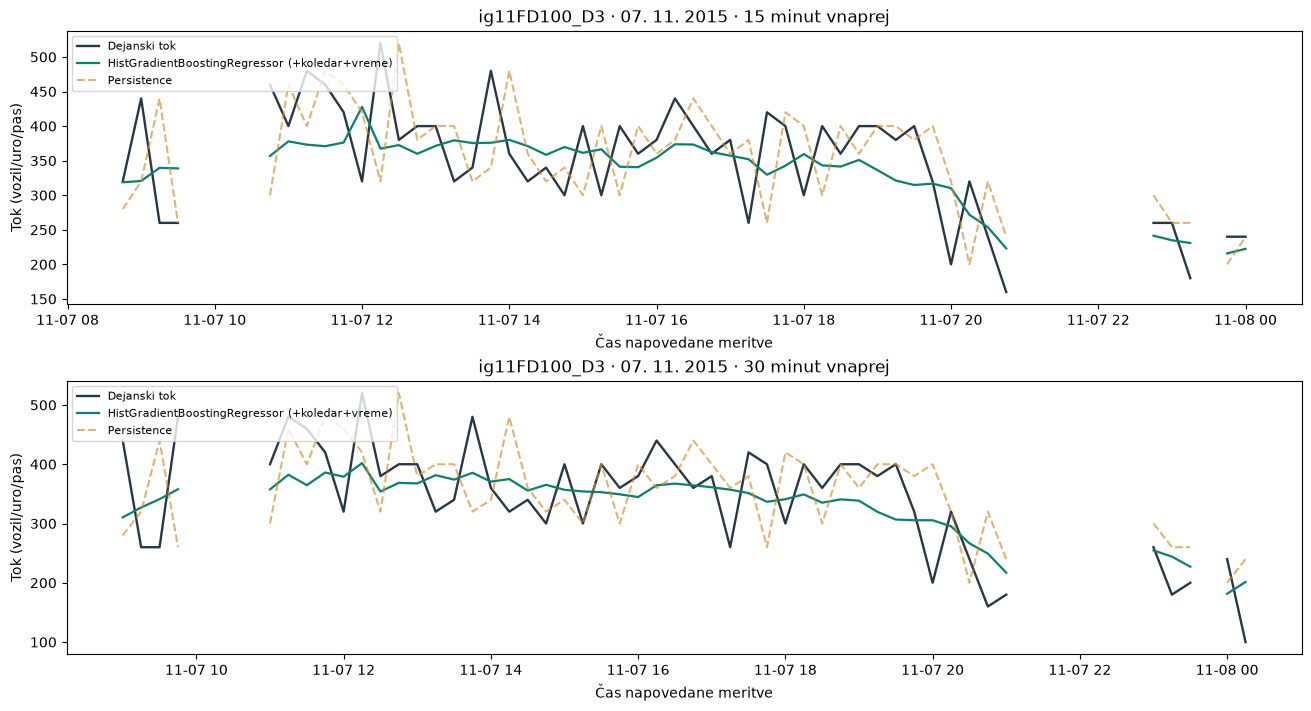

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), layout='constrained')
for ax, horizon in zip(axes, HORIZONS):
    examples = [part for part in forecast_examples if part.horizon_min.iloc[0] == horizon]
    if not examples:
        ax.text(0.5, 0.5, 'Za izbrani detektor ni primerov.', ha='center', transform=ax.transAxes)
        continue
    example = examples[0].sort_values('target_time')
    # Reindex only for drawing: missing eligible forecasts remain visible as gaps.
    grid = pd.date_range(example.target_time.min(), example.target_time.max(),
                         freq=f'{ORIGIN_STEP_MINUTES}min')
    view = example.set_index('target_time').reindex(grid)
    ax.plot(view.index, view.observed, label='Dejanski tok', color='#273746', linewidth=1.7)
    ax.plot(view.index, view.predicted, label=winners[horizon],
            color='#0b806b', linewidth=1.6)
    ax.plot(view.index, view.flow, label='Persistence', color='#d28b26', alpha=0.65, linestyle='--')
    day = example.timestamp.min().strftime('%d. %m. %Y')
    ax.set(title=f'{detector_ids[0]} · {day} · {horizon} minut vnaprej',
           xlabel='Čas napovedane meritve', ylabel='Tok (vozil/uro/pas)')
    ax.legend(loc='upper left', fontsize=8)
fig.savefig(OUTPUT_DIR / 'forecast_vs_observed.png', dpi=150, bbox_inches='tight')
plt.show()


Na prikazanem primeru sem preveril, kako izbrani model sledi dejanskemu toku in kratkotrajnim vrhovom.


### 6.2 Kateri model najbolje napove število vozil?

Za vsoto vozil v naslednjih 15 in 30 minutah sem primerjal RandomForestRegressor, Support Vector Regression z jedrom RBF, XGBRegressor in HistGradientBoostingRegressor ter izbral najmanjši validacijski MAE.


In [10]:
def count_metrics(actual, prediction):
    prediction = np.maximum(np.asarray(prediction), 0)
    actual = np.asarray(actual, dtype=float)
    error = np.abs(actual - prediction)
    return {'Povprečno vozil/pas': actual.mean(), 'MAE [vozil/pas]': error.mean(),
            'RMSE [vozil/pas]': np.sqrt(np.mean((actual - prediction) ** 2)),
            'WAPE [%]': 100 * error.sum() / actual.sum() if actual.sum() else np.nan,
            'Do 3 vozil [%]': 100 * (error <= 3).mean(), 'Primeri': len(actual)}

count_rows, count_full_rows, count_winners = [], [], {}
count_features = feature_sets['weather']
for horizon in HORIZONS:
    frame = horizon_frame(horizon)
    target = f'count_target_{horizon}m'
    count_train = frame.loc[frame.split.eq('train') & frame[target].notna()]
    count_train = count_train.sample(n=min(TRAIN_SAMPLE_SIZE, len(count_train)), random_state=SEED)
    count_val = evaluation_sample(frame.loc[frame.split.eq('validation') & frame[target].notna()])
    full_test = frame.loc[frame.split.eq('test') & frame[target].notna()]
    count_test = evaluation_sample(full_test)
    assert (count_train.timestamp + pd.Timedelta(minutes=horizon) < TRAIN_END).all()
    assert (count_val.timestamp + pd.Timedelta(minutes=horizon) < VAL_END).all()
    assert (full_test.timestamp + pd.Timedelta(minutes=horizon) < YEAR_END).all()
    count_models = {
        'HistGradientBoostingRegressor': make_estimator('hgb', count_features),
        'HistGradientBoostingRegressor (MAE)': make_estimator('hgb', count_features).set_params(loss='absolute_error'),
        'HistGradientBoostingRegressor (300 iteracij, MAE)': make_estimator('hgb', count_features).set_params(
            loss='absolute_error', max_iter=300, max_leaf_nodes=63),
        'RandomForestRegressor': make_estimator('rf', count_features),
        'Support Vector Regression (RBF)': make_estimator('svr', count_features),
        'XGBoost (XGBRegressor)': make_estimator('xgb', count_features),
    }
    val_predictions = {'Persistence': count_val.flow.to_numpy(dtype=float) * horizon / 60}
    training_sizes = {'Persistence': 0}
    for name, model in count_models.items():
        kind = 'svr' if name == 'Support Vector Regression (RBF)' else 'tree'
        training = model_training_rows(count_train, kind)
        training_sizes[name] = len(training)
        with threadpool_limits(limits=N_JOBS):
            model.fit(training[count_features], training[target])
            val_predictions[name] = np.maximum(model.predict(count_val[count_features]), 0)
        print(f'{horizon} min | {name}: validation MAE = '
              f'{mean_absolute_error(count_val[target], val_predictions[name]):.3f}', flush=True)
    val_mae = {name: mean_absolute_error(count_val[target], pred) for name, pred in val_predictions.items()}
    count_winners[horizon] = min(val_mae, key=lambda name: (val_mae[name], name))
    winner = count_winners[horizon]
    print(f'Izbran na validaciji ({horizon} min): {winner}', flush=True)

    predictions = {'Persistence': count_test.flow.to_numpy(dtype=float) * horizon / 60}
    for name, model in count_models.items():
        with threadpool_limits(limits=N_JOBS):
            predictions[name] = model.predict(count_test[count_features])
    for name, prediction in predictions.items():
        count_rows.append({'Obdobje [min]': horizon, 'Model': name,
            'Učni primeri': training_sizes[name], 'Validacijski MAE': val_mae[name],
            **count_metrics(count_test[target], prediction),
            'Validacijski primeri': len(count_val), 'Izbran': name == winner})

    # Only the locked winner and persistence need predictions on the full test set.
    if winner in count_models:
        with threadpool_limits(limits=N_JOBS):
            full_prediction = count_models[winner].predict(full_test[count_features])
    else:
        full_prediction = full_test.flow.to_numpy(dtype=float) * horizon / 60
    for name, prediction in [(winner, full_prediction),
                              ('Persistence', full_test.flow.to_numpy(dtype=float) * horizon / 60)]:
        count_full_rows.append({'Obdobje [min]': horizon, 'Model': name,
            'Učni primeri': training_sizes[name], 'Validacijski MAE': val_mae[name],
            **count_metrics(full_test[target], prediction), 'Izbran': name == winner})
    joblib.dump({'model_name': winner, 'model': count_models.get(winner),
        'features': count_features if winner in count_models else [],
        'detector_mapping': detector_mapping, 'horizon_minutes': horizon,
        'target': 'sum of next 3-minute counts', 'unit': 'vehicles/lane',
        'weather_delay_hours': WEATHER_DELAY_HOURS, 'clip_predictions_at_zero': True,
        'selection_rule': 'lowest validation MAE on shared sample',
        'validation_MAE': val_mae[winner], 'training_samples': training_sizes[winner]},
        OUTPUT_DIR / f'vehicle_count_model_{horizon}m.joblib')
    del frame, count_train, count_val, count_test, full_test, count_models, training, predictions
    gc.collect()

count_results = pd.DataFrame(count_rows).sort_values(['Obdobje [min]', 'Validacijski MAE'])
assert count_results.groupby('Obdobje [min]')[['Primeri', 'Validacijski primeri']].nunique().eq(1).all().all()
count_results.to_csv(OUTPUT_DIR / 'vehicle_count_metrics.csv', index=False)
print('Vsi modeli: isti validation/test vzorec; različni učni obsegi so navedeni v tabeli.')
display(count_results[['Obdobje [min]', 'Model', 'Učni primeri', 'Validacijski MAE',
                       'MAE [vozil/pas]', 'Izbran']].rename(columns={'MAE [vozil/pas]': 'Testni MAE'}).round(2))
count_full_results = pd.DataFrame(count_full_rows).drop_duplicates(['Obdobje [min]', 'Model'])
count_full_results.to_csv(OUTPUT_DIR / 'vehicle_count_full_test.csv', index=False)
count_selected = count_full_results.loc[count_full_results.Izbran]
count_selected.to_csv(OUTPUT_DIR / 'selected_vehicle_count_models.csv', index=False)
print('Izbrana modela: celoten testni nabor.')
display(count_selected[['Obdobje [min]', 'Model', 'Povprečno vozil/pas', 'MAE [vozil/pas]',
                        'RMSE [vozil/pas]', 'WAPE [%]', 'Do 3 vozil [%]', 'Primeri']].round(2))


15 min | HistGradientBoostingRegressor: validation MAE = 10.683


15 min | HistGradientBoostingRegressor (MAE): validation MAE = 10.736


15 min | HistGradientBoostingRegressor (300 iteracij, MAE): validation MAE = 10.474


15 min | RandomForestRegressor: validation MAE = 11.489


15 min | Support Vector Regression (RBF): validation MAE = 14.103


15 min | XGBoost (XGBRegressor): validation MAE = 10.999


... (8 outputs left out)

Vsi modeli: isti validation/test vzorec; različni učni obsegi so navedeni v tabeli.


,Obdobje [min],Model,Učni primeri,Validacijski MAE,Testni MAE,Izbran
3,15,"HistGradientBoostingRegressor (300 iteracij, MAE)",300000,10.47,10.68,True
1,15,HistGradientBoostingRegressor,300000,10.68,10.76,False
2,15,HistGradientBoostingRegressor (MAE),300000,10.74,10.84,False
6,15,XGBoost (XGBRegressor),300000,11.00,10.95,False
4,15,RandomForestRegressor,300000,11.49,11.39,False
5,15,Support Vector Regression (RBF),5000,14.10,14.77,False
0,15,Persistence,0,20.00,20.20,False
10,30,"HistGradientBoostingRegressor (300 iteracij, MAE)",300000,16.98,17.97,True
8,30,HistGradientBoostingRegressor,300000,17.60,18.19,False
9,30,HistGradientBoostingRegressor (MAE),300000,17.75,18.30,False


Izbrana modela: celoten testni nabor.


,Obdobje [min],Model,Povprečno vozil/pas,MAE [vozil/pas],RMSE [vozil/pas],WAPE [%],Do 3 vozil [%],Primeri
0,15,"HistGradientBoostingRegressor (300 iteracij, MAE)",118.15,10.64,13.85,9.00,19.02,233313
2,30,"HistGradientBoostingRegressor (300 iteracij, MAE)",237.88,18.04,23.85,7.58,11.61,227935


Prvotna napaka okoli 3,8 vozila velja za eno 3-minutno meritev; tukaj sem MAE in prag treh vozil računal za celotno obdobje, WAPE pa kot delež skupne absolutne napake v izmerjenem prometu.


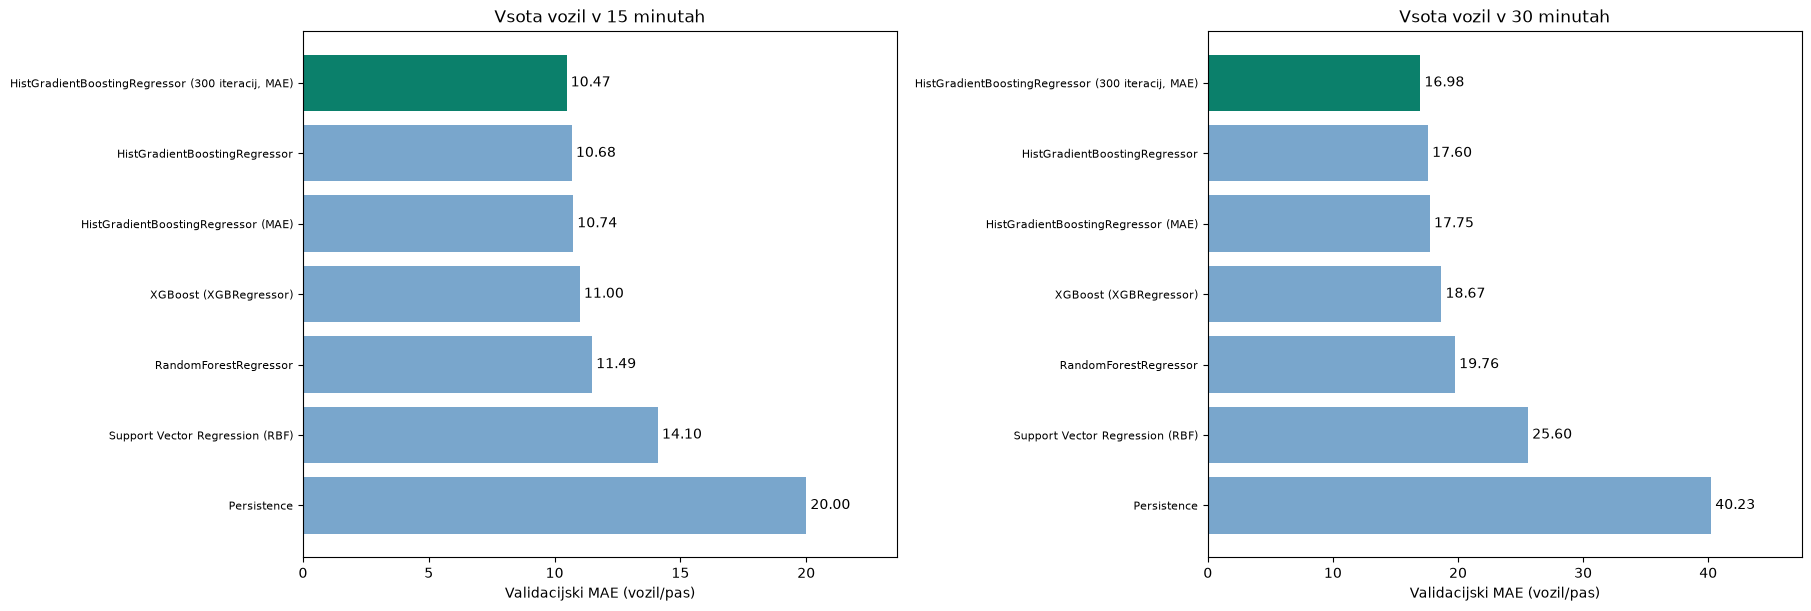

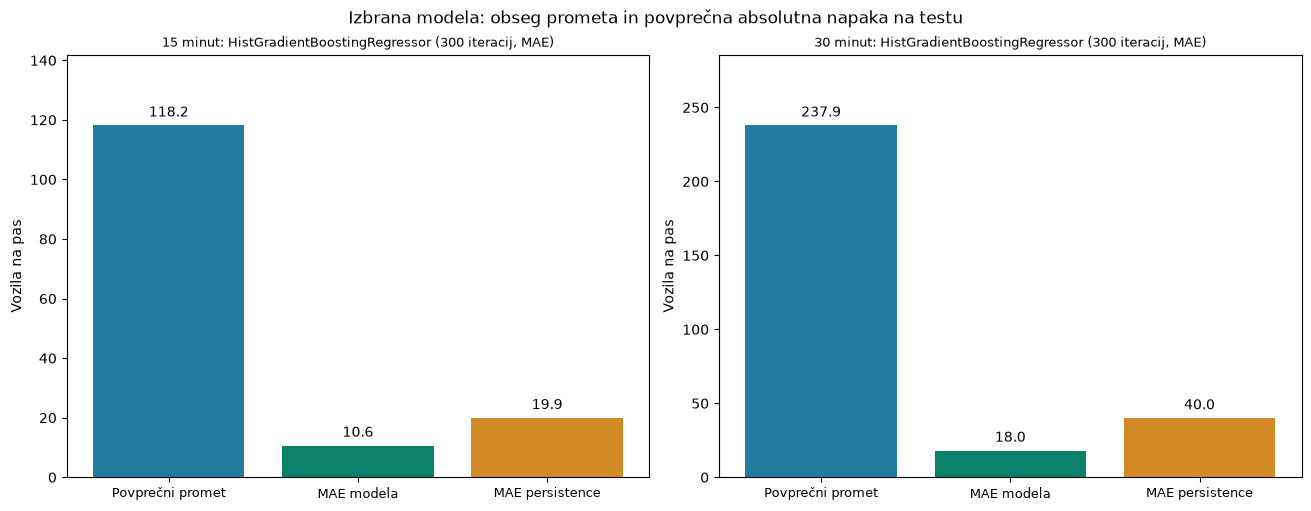

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), layout='constrained')
for ax, horizon in zip(axes, HORIZONS):
    rows = count_results.loc[count_results['Obdobje [min]'].eq(horizon)].sort_values('Validacijski MAE', ascending=False)
    colors = ['#0b806b' if selected else '#79a6cc' for selected in rows.Izbran]
    bars = ax.barh(rows.Model, rows['Validacijski MAE'], color=colors)
    ax.bar_label(bars, fmt='%.2f', padding=3)
    ax.tick_params(axis='y', labelsize=8)
    ax.set(title=f'Vsota vozil v {horizon} minutah', xlabel='Validacijski MAE (vozil/pas)')
    ax.set_xlim(0, rows['Validacijski MAE'].max() * 1.18)
fig.savefig(OUTPUT_DIR / 'vehicle_count_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for ax, horizon in zip(axes, HORIZONS):
    rows = count_full_results.loc[count_full_results['Obdobje [min]'].eq(horizon)].set_index('Model')
    winner = count_winners[horizon]
    model, baseline = rows.loc[winner], rows.loc['Persistence']
    bars = ax.bar(['Povprečni promet', 'MAE modela', 'MAE persistence'],
                  [model['Povprečno vozil/pas'], model['MAE [vozil/pas]'], baseline['MAE [vozil/pas]']],
                  color=['#247ba0', '#0b806b', '#d28b26'])
    ax.bar_label(bars, fmt='%.1f', padding=4)
    ax.set(title=f'{horizon} minut: {winner}', ylabel='Vozila na pas')
    ax.title.set_fontsize(9)
    ax.tick_params(axis='x', labelsize=9)
    ax.margins(y=0.2)
fig.suptitle('Izbrana modela: obseg prometa in povprečna absolutna napaka na testu')
fig.savefig(OUTPUT_DIR / 'vehicle_count_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


In [12]:
# 6.3 Nastavljanje hiperparametrov za skupno število vozil
from IPython.display import Markdown
from sklearn.metrics import f1_score

display(Markdown('### 6.3 Nastavljanje hiperparametrov\n\n'
                 'Preizkusil sem več nastavitev modela HistGradientBoostingRegressor za vsoto vozil '
                 'v 15 in 30 minutah ter izbral najnižji validacijski MAE. '
                 'Za F1 sem uporabil visok promet, ki doseže 90. percentil učnih vrednosti za posamezni horizont.'))

tuning_features = feature_sets['weather']
reference_params = dict(loss='absolute_error', max_iter=300, learning_rate=0.08,
                        max_leaf_nodes=63, min_samples_leaf=40, l2_regularization=1.0)
tuning_options = [
    ('Izhodišče', {}),
    ('Manjši korak', dict(learning_rate=0.05, max_iter=420)),
    ('Večji korak', dict(learning_rate=0.12, max_iter=250)),
    ('Več listov', dict(max_leaf_nodes=95, max_iter=400)),
    ('Manjši listi', dict(max_leaf_nodes=95, min_samples_leaf=25)),
    ('Močnejše omejitve', dict(max_leaf_nodes=31, min_samples_leaf=70, l2_regularization=3.0)),
    ('Manjša regularizacija', dict(l2_regularization=0.1)),
    ('Kvadratna izguba', dict(loss='squared_error')),
]

def tuning_metrics(actual, prediction, high_traffic_threshold):
    actual = np.asarray(actual, dtype=float)
    prediction = np.maximum(np.asarray(prediction, dtype=float), 0)
    return {'MAE': mean_absolute_error(actual, prediction),
            'RMSE': np.sqrt(mean_squared_error(actual, prediction)),
            'F1 (visok promet)': f1_score(actual >= high_traffic_threshold,
                                          prediction >= high_traffic_threshold, zero_division=0)}

tuning_validation_rows, tuning_test_rows, tuned_count_models = [], [], {}
for horizon in HORIZONS:
    frame = horizon_frame(horizon)
    target = f'count_target_{horizon}m'
    complete = frame[target].notna()
    train = frame.loc[frame.split.eq('train') & complete]
    high_traffic_threshold = float(train[target].quantile(0.90))
    train = train.sample(n=min(TRAIN_SAMPLE_SIZE, len(train)), random_state=SEED)
    validation = evaluation_sample(frame.loc[frame.split.eq('validation') & complete])
    test = frame.loc[frame.split.eq('test') & complete]
    train_features = train[tuning_features]
    validation_features = validation[tuning_features]
    best_rank = (np.inf, np.inf)

    with threadpool_limits(limits=N_JOBS):
        for name, changes in tuning_options:
            parameters = {**reference_params, **changes}
            model = make_estimator('hgb', tuning_features).set_params(**parameters)
            model.fit(train_features, train[target])
            metrics = tuning_metrics(validation[target], model.predict(validation_features), high_traffic_threshold)
            tuning_validation_rows.append({'Obdobje [min]': horizon, 'Nastavitev': name, **parameters, **metrics})
            rank = (metrics['MAE'], metrics['RMSE'])
            if rank < best_rank:
                best_rank, best_name, best_model = rank, name, model
            if name == 'Izhodišče':
                reference_model = model
            print(f'{horizon} min | {name}: validacijski MAE {metrics["MAE"]:.3f}', flush=True)

        tuned_count_models[horizon] = {'model': best_model, 'features': tuning_features,
                                       'high_traffic_threshold': high_traffic_threshold, 'configuration': best_name}
        # Evaluate the original and the validation winner on the entire test period.
        test_features = test[tuning_features]
        for label, name, model in [('Izhodišče', 'Izhodišče', reference_model),
                                   ('Izbrani model', best_name, best_model)]:
            metrics = tuning_metrics(test[target], model.predict(test_features), high_traffic_threshold)
            tuning_test_rows.append({'Obdobje [min]': horizon, 'Model': label, 'Nastavitev': name,
                                     'Prag [vozil/pas]': high_traffic_threshold,
                                     'Primeri': len(test), **metrics})
    del frame, train, validation, test, train_features, validation_features, test_features, complete
    gc.collect()

tuning_validation_results = pd.DataFrame(tuning_validation_rows).sort_values(['Obdobje [min]', 'MAE', 'RMSE'])
tuning_test_results = pd.DataFrame(tuning_test_rows)
display(Markdown('**Validacija.** MAE in RMSE sta izražena v vozilih na pas za celotno obdobje.'))
display(tuning_validation_results.round(4).reset_index(drop=True))
display(Markdown('**Celoten testni nabor.** Primerjal sem prvotno nastavitev in zmagovalca validacije.'))
display(tuning_test_results.round(4))


### 6.3 Nastavljanje hiperparametrov

Preizkusil sem več nastavitev modela HistGradientBoostingRegressor za vsoto vozil v 15 in 30 minutah ter izbral najnižji validacijski MAE. Za F1 sem uporabil visok promet, ki doseže 90. percentil učnih vrednosti za posamezni horizont.

15 min | Izhodišče: validacijski MAE 10.474
15 min | Manjši korak: validacijski MAE 10.472
15 min | Večji korak: validacijski MAE 10.498
15 min | Več listov: validacijski MAE 10.452
15 min | Manjši listi: validacijski MAE 10.480
15 min | Močnejše omejitve: validacijski MAE 10.566
15 min | Manjša regularizacija: validacijski MAE 10.472
15 min | Kvadratna izguba: validacijski MAE 10.412
30 min | Izhodišče: validacijski MAE 16.982
30 min | Manjši korak: validacijski MAE 16.962
30 min | Večji korak: validacijski MAE 16.954
30 min | Več listov: validacijski MAE 16.858
30 min | Manjši listi: validacijski MAE 16.886
30 min | Močnejše omejitve: validacijski MAE 17.173
30 min | Manjša regularizacija: validacijski MAE 16.975
30 min | Kvadratna izguba: validacijski MAE 16.831


**Validacija.** MAE in RMSE sta izražena v vozilih na pas za celotno obdobje.

,Obdobje [min],Nastavitev,loss,max_iter,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,MAE,RMSE,F1 (visok promet)
0,15,Kvadratna izguba,squared_error,300,0.08,63,40,1.0,10.4115,13.5628,0.7569
1,15,Več listov,absolute_error,400,0.08,95,40,1.0,10.4522,13.6594,0.7489
2,15,Manjši korak,absolute_error,420,0.05,63,40,1.0,10.4716,13.7116,0.7550
3,15,Manjša regularizacija,absolute_error,300,0.08,63,40,0.1,10.4721,13.7009,0.7560
4,15,Izhodišče,absolute_error,300,0.08,63,40,1.0,10.4745,13.6996,0.7515
5,15,Manjši listi,absolute_error,300,0.08,95,25,1.0,10.4803,13.6948,0.7517
6,15,Večji korak,absolute_error,250,0.12,63,40,1.0,10.4975,13.7198,0.7517
7,15,Močnejše omejitve,absolute_error,300,0.08,31,70,3.0,10.5663,13.8216,0.7525
8,30,Kvadratna izguba,squared_error,300,0.08,63,40,1.0,16.8306,22.1585,0.7909
9,30,Več listov,absolute_error,400,0.08,95,40,1.0,16.8580,22.3264,0.7911


**Celoten testni nabor.** Primerjal sem prvotno nastavitev in zmagovalca validacije.

,Obdobje [min],Model,Nastavitev,Prag [vozil/pas],Primeri,MAE,RMSE,F1 (visok promet)
0,15,Izhodišče,Izhodišče,170.0,233313,10.6387,13.8522,0.7426
1,15,Izbrani model,Kvadratna izguba,170.0,233313,10.6061,13.7654,0.7401
2,30,Izhodišče,Izhodišče,337.0,227935,18.0422,23.8525,0.7733
3,30,Izbrani model,Kvadratna izguba,337.0,227935,17.9847,23.6678,0.7721


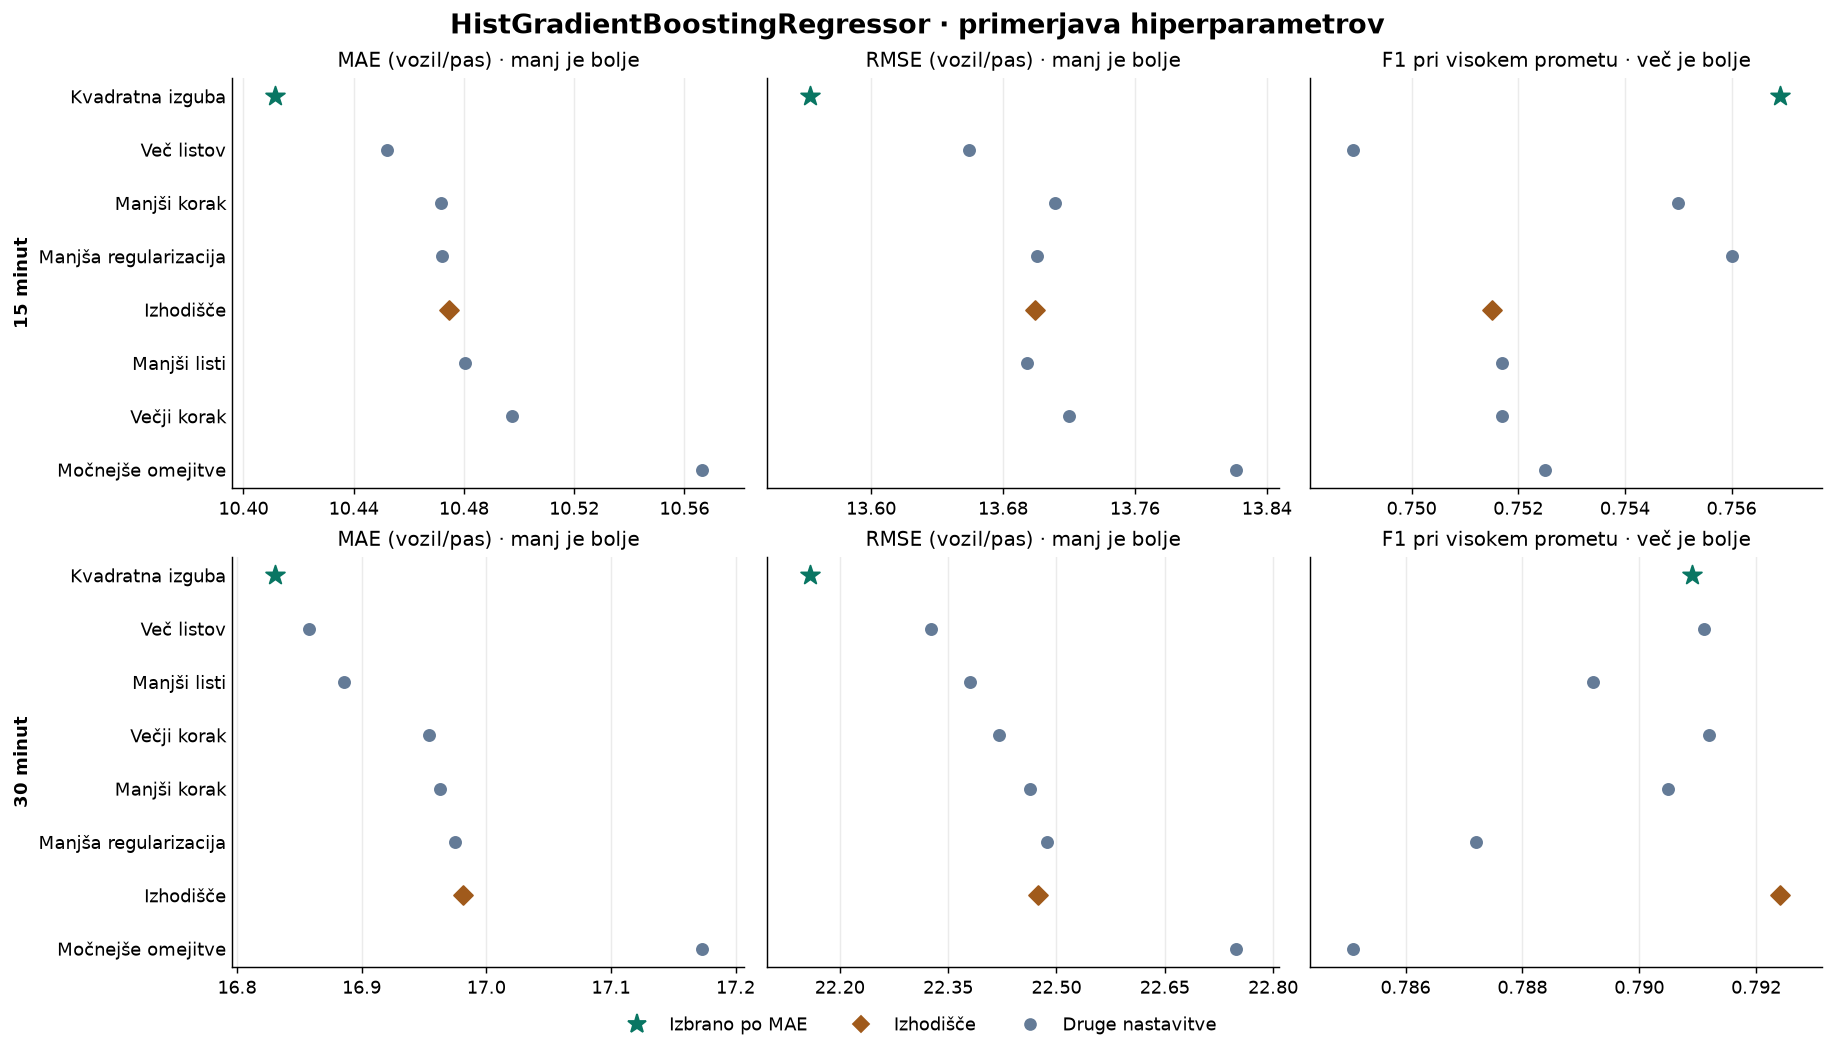

In [13]:
# 6.4 Vizualna primerjava nastavitev na validaciji
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

metrics = [
    ('MAE', 'MAE (vozil/pas) · manj je bolje'),
    ('RMSE', 'RMSE (vozil/pas) · manj je bolje'),
    ('F1 (visok promet)', 'F1 pri visokem prometu · več je bolje'),
]
fig, axes = plt.subplots(len(HORIZONS), len(metrics), figsize=(14, 8),
                         sharey='row', layout='constrained', squeeze=False)
for row, horizon in enumerate(HORIZONS):
    scores = tuning_validation_results.loc[tuning_validation_results['Obdobje [min]'].eq(horizon)]
    scores = scores.sort_values(['MAE', 'RMSE']).reset_index(drop=True)
    selected = scores.index == 0
    reference = scores['Nastavitev'].eq('Izhodišče') & ~selected
    other = ~(selected | reference)
    for col, (metric, title) in enumerate(metrics):
        ax = axes[row, col]
        ax.scatter(scores.loc[other, metric], scores.index[other], s=38, color='#647b97', zorder=3)
        ax.scatter(scores.loc[reference, metric], scores.index[reference],
                   s=55, color='#a05a1b', marker='D', zorder=3)
        ax.scatter(scores.loc[selected, metric], scores.index[selected],
                   s=120, color='#097663', marker='*', zorder=4)
        ax.set_title(title, fontsize=11)
        ax.xaxis.set_major_locator(MaxNLocator(5))
        ax.margins(x=0.10)
        ax.grid(axis='x', alpha=0.25)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(axis='y', length=0)
    axes[row, 0].set_yticks(scores.index, labels=scores['Nastavitev'])
    axes[row, 0].set_ylabel(f'{horizon} minut', fontweight='bold')
    axes[row, 0].invert_yaxis()

legend = [
    Line2D([], [], marker='*', linestyle='None', color='#097663', markersize=11, label='Izbrano po MAE'),
    Line2D([], [], marker='D', linestyle='None', color='#a05a1b', markersize=6, label='Izhodišče'),
    Line2D([], [], marker='o', linestyle='None', color='#647b97', markersize=6, label='Druge nastavitve'),
]
fig.suptitle('HistGradientBoostingRegressor · primerjava hiperparametrov', fontsize=15, fontweight='bold')
fig.legend(handles=legend, loc='outside lower center', ncols=3, frameon=False)
plt.show()


Nove modele sem izbral na validaciji, za neodvisno potrditev pa potrebujem novo obdobje, saj je bil trenutni test že pregledan.


## 7. Moj sklep

Za posamezno meritev in vsoto vozil sem model za vsak horizont izbral po najmanjšem validacijskem MAE ter ga nato ocenil na celotnem testnem obdobju.
